# PostgreSQL JSONB & pgvector

You do not always need a separate NoSQL or vector database. PostgreSQL stores **semi-structured JSON** in the `jsonb` type with indexes, and the **pgvector** extension adds a `vector` type with similarity search. With both, one database can hold relational data, flexible attributes and embeddings for AI search.

**After this lesson you can:**

1. Store, query and index `jsonb` documents.
2. Explain embeddings and vector similarity.
3. Create embeddings with a free local model (Ollama), store them with pgvector, and search by meaning.
4. Speed up vector search with an HNSW index and measure its recall.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads and loads the sample data

engine = create_engine(datasets.ensure_chinook())  # starts PostgreSQL in Docker and loads Chinook on first use

def q(sql: str, **params) -> pd.DataFrame:
    """Run a SQL query and return the result as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

lab = create_engine(datasets.POSTGRES_URL.format(db="course"))   # a separate database for experiments

def run(sql: str) -> None:
    """Execute SQL statements (DDL/DML) in the lab database, in one transaction."""
    with lab.begin() as conn:
        if "$$" in sql:                       # function bodies contain ";" -> send the whole script at once
            conn.execute(text(sql))
            return
        for stmt in [s for s in sql.split(";") if s.strip()]:
            conn.execute(text(stmt))

def lq(sql: str, **params) -> pd.DataFrame:
    with lab.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

## 1. JSONB

`jsonb` stores JSON in a binary, indexed form.

| Operator | Meaning | Example |
| :--- | :--- | :--- |
| `->` / `->>` | get a field as JSON / as text | `attrs->>'brand'` |
| `#>>` | get a nested path as text | `attrs#>>'{size,width}'` |
| `@>` | contains (uses a GIN index) | `attrs @> '{"color": "red"}'` |
| `?` | key exists | `attrs ? 'warranty'` |
| `jsonb_set` | update a value | `jsonb_set(attrs, '{price}', '25')` |

In [2]:
run("""
DROP TABLE IF EXISTS product;
CREATE TABLE product (id serial PRIMARY KEY, name text, attrs jsonb NOT NULL);
INSERT INTO product (name, attrs) VALUES
 ('Headphones X1', '{"category": "audio", "brand": "Sonix", "wireless": true, "battery_h": 30, "colors": ["black", "white"]}'),
 ('Vinyl: Kind of Blue', '{"category": "music", "format": "LP", "artist": "Miles Davis", "year": 1959}'),
 ('Speaker S2', '{"category": "audio", "brand": "Sonix", "wireless": true, "battery_h": 12, "waterproof": "IP67"}'),
 ('Turntable T9', '{"category": "audio", "brand": "Analoga", "wireless": false, "speeds": [33, 45]}');
CREATE INDEX product_attrs_gin ON product USING gin (attrs)
""")
print(lq("SELECT name, attrs->>'brand' AS brand, (attrs->>'battery_h')::int AS battery FROM product WHERE attrs @> '{\"wireless\": true}'"))
print(lq("SELECT name FROM product WHERE attrs ? 'waterproof'"))
print(lq("SELECT name, jsonb_array_elements_text(attrs->'colors') AS color FROM product WHERE attrs ? 'colors'"))

            name  brand  battery
0  Headphones X1  Sonix       30
1     Speaker S2  Sonix       12
         name
0  Speaker S2
            name  color
0  Headphones X1  black
1  Headphones X1  white


Use regular columns for fields that every row has and that you join or filter on often; use `jsonb` for optional, varying attributes.

## 2. Embeddings and Similarity

An **embedding** is a vector of numbers that represents the meaning of a text (or image). Texts with similar meaning get vectors that point in similar directions. **Cosine similarity** measures the angle between two vectors:

$$
\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\lVert \mathbf{a} \rVert \, \lVert \mathbf{b} \rVert}
$$

pgvector provides the operators `<=>` (cosine distance $= 1 - \cos$), `<->` (Euclidean distance) and `<#>` (negative inner product).

The cell creates embeddings with **nomic-embed-text**, a free embedding model, served by **Ollama** on your machine (`ollama pull nomic-embed-text`).

In [3]:
import json
import urllib.request

import numpy as np

OLLAMA = "http://localhost:11434"

def embed(texts: list[str]) -> np.ndarray:
    req = urllib.request.Request(f"{OLLAMA}/api/embed", data=json.dumps({"model": "nomic-embed-text", "input": texts}).encode(),
                                 headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=300) as resp:
        return np.array(json.load(resp)["embeddings"], dtype=np.float32)

v = embed(["a sad song about lost love", "a heartbreaking ballad", "fast heavy metal guitar riff"])
cos = lambda a, b: float(a @ b / np.linalg.norm(a) / np.linalg.norm(b))
print(f"embedding dimension: {v.shape[1]}")
print(f"sad song vs ballad    : {cos(v[0], v[1]):.3f}")
print(f"sad song vs metal riff: {cos(v[0], v[2]):.3f}")

embedding dimension: 768
sad song vs ballad    : 0.783
sad song vs metal riff: 0.360


## 3. Semantic Search over Chinook Albums

The cell embeds every album as "album title by artist", stores the vectors in a pgvector column and searches by meaning: the query words do not need to appear in the title.

In [4]:
albums = q("SELECT al.album_id, al.title, ar.name AS artist FROM album al JOIN artist ar USING (artist_id) ORDER BY al.album_id")
docs = [f"{t} by {a}" for t, a in zip(albums["title"], albums["artist"])]
import time

t0 = time.perf_counter()
vectors = np.vstack([embed(docs[i:i + 64]) for i in range(0, len(docs), 64)])
print(f"{len(docs)} albums embedded in {time.perf_counter() - t0:.1f} s, matrix {vectors.shape}")

dim = vectors.shape[1]
run(f"""CREATE EXTENSION IF NOT EXISTS vector;
        DROP TABLE IF EXISTS album_vec;
        CREATE TABLE album_vec (album_id int PRIMARY KEY, label text, embedding vector({dim}))""")
with lab.begin() as conn:
    conn.execute(text("INSERT INTO album_vec VALUES (:i, :l, :e)"),
                 [{"i": int(i), "l": d, "e": str(vec.tolist())} for i, d, vec in zip(albums["album_id"], docs, vectors)])

def search(query: str, k: int = 5) -> pd.DataFrame:
    qv = str(embed([query])[0].tolist())
    return lq("SELECT label, round((1 - (embedding <=> CAST(:q AS vector)))::numeric, 3) AS cosine "
              "FROM album_vec ORDER BY embedding <=> CAST(:q AS vector) LIMIT :k", q=qv, k=k)

for query in ["classical orchestra and symphonies", "brazilian music", "live concert recording"]:
    print(f"\nquery: {query!r}")
    print(search(query).to_string(index=False))

347 albums embedded in 12.2 s, matrix (347, 768)



query: 'classical orchestra and symphonies'
                                                                               label  cosine
     Haydn: Symphonies 99 - 104 by Royal Philharmonic Orchestra & Sir Thomas Beecham   0.717
    Mozart: Symphonies Nos. 40 & 41 by Berliner Philharmoniker & Herbert Von Karajan   0.690
                   Nielsen: The Six Symphonies by Göteborgs Symfoniker & Neeme Järvi   0.675
Beethoven: Symphony No. 6 'Pastoral' Etc. by Otto Klemperer & Philharmonia Orchestra   0.675
            Bach: The Brandenburg Concertos by Orchestra of The Age of Enlightenment   0.672

query: 'brazilian music'
                                                                          label  cosine
                                         Chill: Brazil (Disc 1) by Marcos Valle   0.688
                                 Chill: Brazil (Disc 2) by Antônio Carlos Jobim   0.678
Radio Brasil (O Som da Jovem Vanguarda) - Seleccao de Henrique Amaro by O Rappa   0.677
                   

## 4. HNSW Index: Fast Approximate Search

Exact search compares the query with every vector: $O(n)$. An **HNSW** (Hierarchical Navigable Small World) index builds a graph of neighbouring vectors and walks it, which is much faster on large tables but **approximate**: it can miss some true nearest neighbours. **Recall@k** measures the share of the true top-*k* results that the index returns.

The experiment adds 50,000 random vectors (synthetic) to make the table large, then compares exact search with HNSW search for 30 queries.

In [5]:
rng = np.random.default_rng(0)
noise = rng.normal(size=(50_000, dim)).astype(np.float32)
raw = lab.raw_connection()
with raw.cursor() as cur, cur.copy("COPY album_vec (album_id, label, embedding) FROM STDIN") as cp:
    for i, vec in enumerate(noise):
        cp.write_row((100_000 + i, "noise", "[" + ",".join(f"{x:.4f}" for x in vec) + "]"))
raw.commit(); raw.close()
queries = [str(x.tolist()) for x in embed([f"music like {a}" for a in albums["artist"].sample(30, random_state=1)])]

def topk(qv, use_index: bool, k=10):
    with lab.begin() as conn:
        conn.execute(text(f"SET LOCAL enable_indexscan = {'on' if use_index else 'off'}"))
        conn.execute(text("SET LOCAL hnsw.ef_search = 40"))
        t = time.perf_counter()
        ids = conn.execute(text("SELECT album_id FROM album_vec ORDER BY embedding <=> CAST(:q AS vector) LIMIT :k"),
                           {"q": qv, "k": k}).scalars().all()
        return ids, (time.perf_counter() - t) * 1000

exact = [topk(qv, False) for qv in queries]
t = time.perf_counter()
run("SET LOCAL maintenance_work_mem = '512MB'; "          # keep the HNSW graph in memory while building: much faster
    "SET LOCAL max_parallel_maintenance_workers = 0; "      # parallel builds need more shared memory than Docker's default
    "CREATE INDEX album_vec_hnsw ON album_vec USING hnsw (embedding vector_cosine_ops)")
build_s = time.perf_counter() - t
approx = [topk(qv, True) for qv in queries]
recall = np.mean([len(set(a[0]) & set(e[0])) / 10 for a, e in zip(approx, exact)])
exact_ms, approx_ms = np.median([e[1] for e in exact]), np.median([a[1] for a in approx])
print(f"rows: {lq('SELECT count(*) AS n FROM album_vec')['n'][0]:,} | HNSW build {build_s:.1f} s")
print(f"exact search median {exact_ms:.1f} ms | HNSW median {approx_ms:.1f} ms | recall@10 = {recall:.2f}")

rows: 50,347 | HNSW build 80.4 s
exact search median 175.0 ms | HNSW median 1.9 ms | recall@10 = 0.97


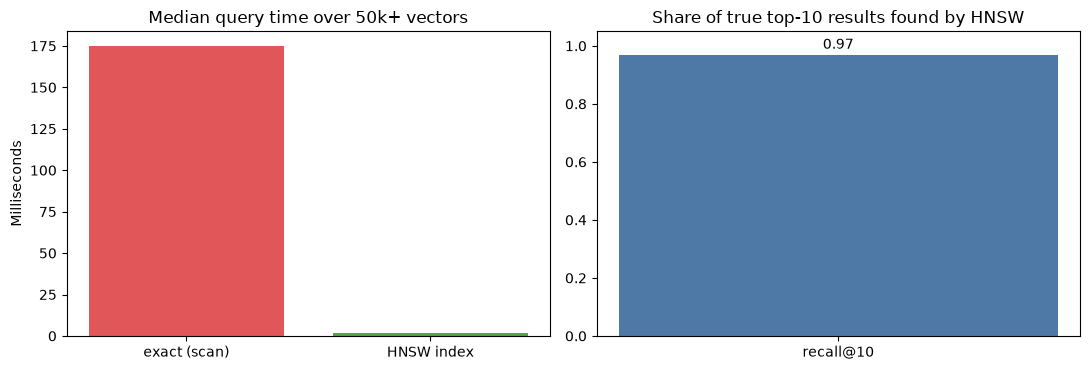

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(["exact (scan)", "HNSW index"], [exact_ms, approx_ms], color=["#E15759", "#59A14F"])
ax1.set(title="Median query time over 50k+ vectors", ylabel="Milliseconds")
ax2.bar(["recall@10"], [recall], color="#4E79A7")
ax2.set(ylim=(0, 1.05), title="Share of true top-10 results found by HNSW")
ax2.text(0, recall + 0.02, f"{recall:.2f}", ha="center")
plt.tight_layout()
plt.show()

*Insight: Start with PostgreSQL + pgvector when your application already uses PostgreSQL: one database, transactions, joins between vectors and business data, and HNSW indexes that are fast enough for millions of vectors. Move to a dedicated vector database (M28) only when scale or features require it.*

## Real-World Use Case or Analogy

`jsonb` is like a **notes field with structure** on a customer card: each customer can have different extra details, and you can still search them. Embeddings are like **placing every book on a giant map** where books about similar topics stand close together; semantic search is "show me the books near this point", even if they share no words with the question.

Retrieval-augmented generation (RAG, M28) uses exactly this: documents are embedded and stored (often in pgvector), the user's question is embedded, and the nearest documents are given to an LLM as context.